# Curricula with custom difficulties

A `Curriculum` samples items whose difficulty rank (quantile) is below a competence `c(t)`, growing from `start` to
`end` along `length` epochs or steps. Difficulties can be anything : here, the noise level of recordings.

We first look at the schedules, then train a minimal pitch estimator (an MLP on log-mel spectrograms) on tones with
different signal-to-noise ratios, with and without a curriculum.

In [1]:
import math, tempfile, collections
from pathlib import Path
import numpy as np
import soundfile as sf
import torch, torch.nn as nn
import torchaudio
import matplotlib.pyplot as plt
from acids_dataset.datasets import AudioDataset
from acids_dataset.sampling import Curriculum

SR = 16000
torch.manual_seed(0); np.random.seed(0)

## Anatomy of a curriculum

The competence follows a `"linear"`, `"sqrt"` (fast growth first) or `"exp"` (slow growth first) schedule. With
`mode="threshold"`, items above the competence have a weight of 0 ; with `mode="soft"`, weights decrease smoothly
(sigmoid with `temperature`).

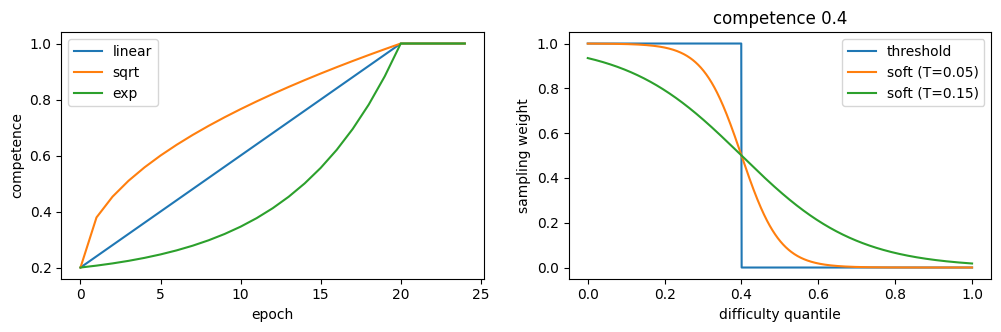

In [2]:
difficulty = np.random.rand(1000)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
for schedule in Curriculum.schedules:
    c = Curriculum(difficulty, start=0.2, end=1., length=20, schedule=schedule)
    competences = []
    for epoch in range(25):
        c.set_epoch(epoch); competences.append(c.competence)
    axes[0].plot(competences, label=schedule)
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("competence"); axes[0].legend()

order = np.argsort(difficulty)
for mode, temperature in [("threshold", None), ("soft", 0.05), ("soft", 0.15)]:
    c = Curriculum(difficulty, start=0.4, length=10, mode=mode, **({"temperature": temperature} if temperature else {}))
    axes[1].plot(np.linspace(0, 1, len(order)), c.weights().numpy()[order], label=mode + ("" if temperature is None else " (T=%.2f)" % temperature))
axes[1].set_xlabel("difficulty quantile"); axes[1].set_ylabel("sampling weight"); axes[1].set_title("competence 0.4"); axes[1].legend()
plt.show()

## A dataset of noisy tones

Each file is a harmonic tone with a random fundamental frequency, at a given SNR. The SNR and the f0 are written in
the file names, and extracted with `meta_regexp` (placeholders match word characters : letters, digits and `_`, such
that values like `-5` or `123.4` must be encoded differently, e.g. `m5` or `123p4`).

In [3]:
root = Path(tempfile.mkdtemp()) / "noisy_tones"
root.mkdir()
t = torch.arange(SR) / SR
snrs = [30, 12, 6, 0]
for snr in snrs:
    for i in range(30):
        f0 = float(np.exp(np.random.uniform(np.log(100), np.log(800))))
        tone = sum(torch.sin(2 * math.pi * f0 * k * t + np.random.rand() * 6.28) / k for k in range(1, 8) if f0 * k < SR / 2)
        tone = tone / tone.std()
        x = tone + 10 ** (-snr / 20) * torch.randn(len(t))
        sf.write(root / f"tone_snr{snr}_f{round(f0)}_{i}.wav", (0.2 * x / x.abs().max()).numpy(), SR)

dataset = AudioDataset(root, sr=SR, chunk_length=0.25, meta_regexp=["**/tone_snr{{snr}}_f{{f0}}_*.wav"],
                       output_pattern="{waveform,index}")
item_snr = np.array([float(s) for s in dataset.item_labels("snr")])
item_f0 = torch.tensor([float(f) for f in dataset.item_labels("f0")])
print(len(dataset), "items, SNRs :", collections.Counter(item_snr.tolist()))

480 items, SNRs : Counter({0.0: 120, 12.0: 120, 30.0: 120, 6.0: 120})


The difficulty of an item is its noise level : `-snr`. Any array with one value per item can be given (from
annotations, a pre-trained model, descriptors...). Unknown difficulties (NaN) are ranked in the middle.

In [4]:
curricula = {
    "uniform": None,
    "curriculum (clean first)": lambda: Curriculum(-item_snr, start=0.25, end=1., length=8),
    "anti-curriculum (noisy first)": lambda: Curriculum(item_snr, start=0.25, end=1., length=8),
}

## A minimal pitch estimator

An MLP on the time-averaged log-mel spectrogram predicts `log2(f0)`. The error is measured in semitones, per SNR.

In [5]:
class TinyPitch(nn.Module):
    def __init__(self):
        super().__init__()
        self.mel = torchaudio.transforms.MelSpectrogram(SR, n_fft=1024, hop_length=256, n_mels=80)
        self.net = nn.Sequential(nn.LayerNorm(80), nn.Linear(80, 64), nn.GELU(), nn.Linear(64, 1))

    def forward(self, x):
        return self.net(torch.log(self.mel(x[:, 0]) + 1e-5).mean(-1))[:, 0] + math.log2(300)

def evaluate(model):
    with torch.no_grad():
        batch = dataset.get(slice(0, len(dataset)))
        error = 12 * (model(batch["waveform"]) - torch.log2(item_f0[batch["index"]])).abs()
    return {snr: error[torch.from_numpy(item_snr[batch["index"].numpy()] == snr)].median().item() for snr in snrs}

def train(make_curriculum, n_epochs=16, seed=0):
    torch.manual_seed(seed)
    model = TinyPitch()
    optimizer = torch.optim.Adam(model.parameters(), lr=3e-3)
    curriculum = make_curriculum() if make_curriculum else None
    loader = dataset.get_loader(batch_size=16, curriculum=curriculum, seed=seed, max_samples=128)
    history = []
    for epoch in range(n_epochs):
        loader.sampler.set_epoch(epoch)
        for batch in loader:
            loss = (model(batch["waveform"]) - torch.log2(item_f0[batch["index"]])).abs().mean()
            optimizer.zero_grad(); loss.backward(); optimizer.step()
        history.append(evaluate(model))
    return history

results = {name: train(make) for name, make in curricula.items()}

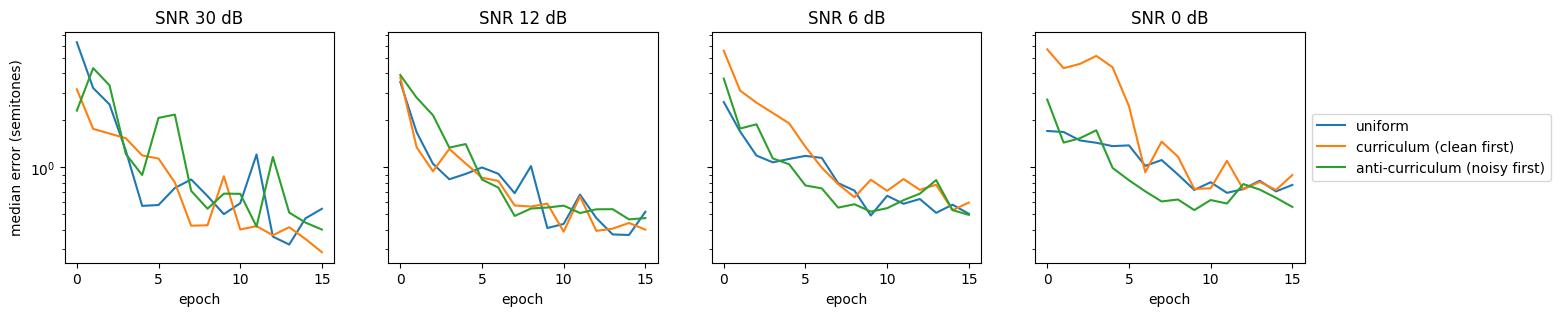

final median error                  30 dB    12 dB     6 dB     0 dB
uniform                              0.54     0.52     0.50     0.77
curriculum (clean first)             0.29     0.40     0.60     0.89
anti-curriculum (noisy first)        0.40     0.47     0.50     0.56


In [6]:
fig, axes = plt.subplots(1, len(snrs), figsize=(16, 3), sharey=True)
for ax, snr in zip(axes, snrs):
    for name, history in results.items():
        ax.plot([h[snr] for h in history], label=name)
    ax.set_title("SNR %d dB" % snr); ax.set_xlabel("epoch"); ax.set_yscale("log")
axes[0].set_ylabel("median error (semitones)"); axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5)); plt.show()

print("%-32s" % "final median error" + "".join("%9s" % ("%d dB" % s) for s in snrs))
for name, history in results.items():
    print("%-32s" % name + "".join("%9.2f" % history[-1][s] for s in snrs))

Results depend on the task and the model : curricula do not always help, and it is worth comparing them with uniform
sampling (with several seeds) on your own problem. `acids_dataset` makes such comparisons cheap, as the curriculum
is only a sampler option.

## Difficulties that change during training

Difficulties can also be given by a callable `difficulty(epoch, step)`, evaluated when the sampler draws items, e.g.
to follow scores re-computed by an external model, or here to move the focus from clean to noisy items :

In [7]:
def moving_focus(epoch, step):
    target = 30 - 5 * epoch                                  # the "ideal" SNR moves from 30 dB to 0 dB
    return np.abs(item_snr - target)

curriculum = Curriculum(moving_focus, start=0.25, end=0.25, length=1)  # constant competence : 25 % of items
sampler = dataset.get_sampler(curriculum=curriculum, seed=0, max_samples=400)
for epoch in range(0, 8, 2):
    sampler.set_epoch(epoch)
    print("epoch %d :" % epoch, dict(sorted(collections.Counter(item_snr[i] for i in sampler).items())))

epoch 0 : {30.0: 400}
epoch 2 : {12.0: 400}
epoch 4 : {12.0: 400}
epoch 6 : {0.0: 400}


## Step-based curricula

With `unit="step"`, the competence grows with training steps, given by `curriculum.step()` (called by the Lightning
callback, see the next notebook). Items are drawn by blocks of `block_size` items (1024 by default), with the
competence at the current step. To use smaller blocks, a `WeightedItemSampler` can be built directly and given to a
`DataLoader` :

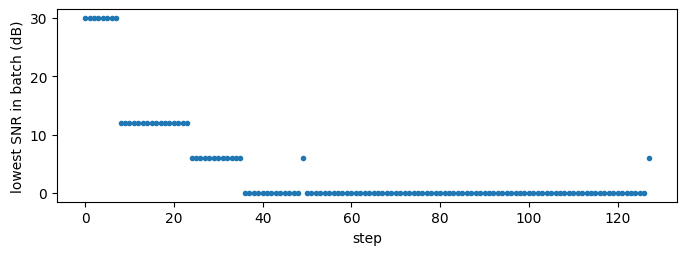

In [8]:
from acids_dataset.sampling import WeightedItemSampler
curriculum = Curriculum(-item_snr, start=0.25, length=40, unit="step")
sampler = WeightedItemSampler(len(dataset), curriculum=curriculum, num_samples=2048, seed=0, block_size=64)
loader = torch.utils.data.DataLoader(dataset, batch_size=16, sampler=sampler)
snr_per_step = []
for step, batch in enumerate(loader):
    snr_per_step.append(item_snr[batch["index"].numpy()].min())
    curriculum.step()
plt.figure(figsize=(8, 2.5)); plt.plot(snr_per_step, ".")
plt.xlabel("step"); plt.ylabel("lowest SNR in batch (dB)"); plt.show()